# Projet 2 : suivi des entraînements

Ce notebook relit les fichiers `runs/*/results.csv` écrits par Ultralytics. On peut le relancer à tout moment pendant la campagne pour voir où en sont les modèles. Tous les scores sont sur la **validation** : le test reste pour la fin.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path("..").resolve()))   # rend le dossier projet2_foot importable
import matplotlib.pyplot as plt
import pandas as pd

RUNS = Path("..") / "runs"
runs = {d.name: pd.read_csv(d / "results.csv").rename(columns=str.strip) for d in sorted(RUNS.iterdir()) if (d / "results.csv").exists()}
for name, r in runs.items():
    state = "terminé" if (RUNS / name / ".done").exists() else "en cours"
    print(f"{name} : {len(r)} epochs, {state}")

yolo11n_640_seed0 : 76 epochs, en cours


## Meilleur score de chaque entraînement

In [2]:
best = pd.DataFrame({name: r.loc[r["metrics/mAP50-95(B)"].idxmax(), ["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]]
                     for name, r in runs.items()}).T
best.round(3)

,epoch,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
yolo11n_640_seed0,71.0,0.932,0.687,0.734,0.477


## Courbes de validation

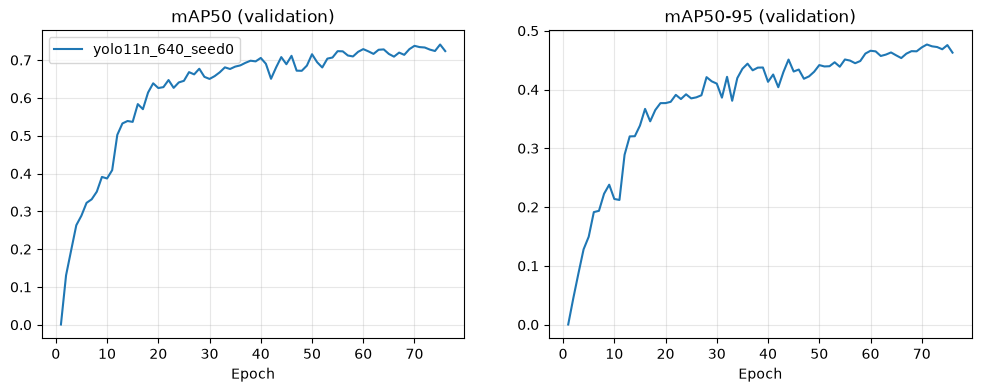

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, r in runs.items():
    axes[0].plot(r["epoch"], r["metrics/mAP50(B)"], label=name)
    axes[1].plot(r["epoch"], r["metrics/mAP50-95(B)"], label=name)
for ax, t in zip(axes, ["mAP50 (validation)", "mAP50-95 (validation)"]):
    ax.set_title(t); ax.set_xlabel("Epoch"); ax.grid(alpha=.3)
axes[0].legend()
plt.show()

## Scores par classe

Ultralytics enregistre les scores par classe dans le log de fin d'entraînement. Cette partie se remplit dès qu'un entraînement est terminé.

In [4]:
import re
for log in sorted(RUNS.glob("*.log")):
    text = log.read_text(errors="ignore").replace("\r", "\n")
    lines = [l for l in text.splitlines() if re.match(r"\s+(all|ball|player|referee)\s+\d", l)]
    if lines:
        print(log.stem)
        print("        Classe  Images  Objets  Précision  Rappel  mAP50  mAP50-95")
        print("\n".join(lines[-4:]), "\n")

yolo11n_640
        Classe  Images  Objets  Précision  Rappel  mAP50  mAP50-95
                   all         49       1174      0.895      0.708      0.728      0.472
                   all         49       1174      0.858      0.712      0.724      0.469
                   all         49       1174       0.92      0.709      0.741      0.476
                   all         49       1174      0.922      0.694      0.724      0.463 

